# Salon Experiment & Causal Analysis — CUPED and Regression Robustness

> **Synthetic data:** These records are fictional. The generator injects 6% A/B and 4% policy service-revenue multipliers for analysis practice; neither is an empirical finding, and neither is hard-coded into the estimators below.

The analysis follows client-level randomization and intention-to-treat (ITT), with one row for each of the 24,000 assigned clients. Clients with zero experiment-period revenue remain in the cohort. Appointment rows are summed to client outcomes, not treated as independent randomized observations. The raw CSVs are read only.

## 1. Experiment design and estimands

- **Unit of randomization / analysis:** client (`client_id`).
- **Assignment:** 12,000 Control and 12,000 Treatment clients from `experiment_assignments.csv`.
- **Primary outcome:** each assigned client's total net service revenue in the inclusive experiment window, 2026-09-01 through 2026-10-31.
- **Unadjusted ITT effect:** Treatment mean minus Control mean, including clients with zero experiment-period revenue.
- **Pre-experiment covariates:** each client's service revenue and appointment count from all available historical appointments before 2026-09-01; plus signup age, retention segment, and preferred outlet region. July–August 2026 is pre-experiment but after the simulated policy start, so it is not pre-policy information. A pre-July covariate sensitivity is included.

**CUPED:** `Y_adjusted = Y - theta * (X - mean(X))`, where `theta = Cov(Y, X) / Var(X)`. The single client-level baseline revenue covariate is pre-experiment service revenue. Adjustment is intended to improve precision when the covariate predicts outcome and is not affected by A/B assignment. Random assignment, consistent outcome measurement, and a valid pre-experiment covariate are required. CUPED does not fix a biased or mismeasured outcome.

**Regression adjustment:** client-level OLS of outcome on treatment assignment and pre-experiment revenue, appointment count, signup age, retention segment, and preferred outlet region, with HC3 heteroskedasticity-robust standard errors. No post-experiment variable is included as a covariate.

The A/B window overlaps the simulated outlet policy period. Randomization permits an ITT comparison within this generated policy environment, but CUPED/regression do not separate the policy effect. The dataset is artificial; the estimates cannot establish real salon business effects.

## 2. Load raw data and validate the randomized cohort

The setup locates the project root and loads the three required CSVs. It checks schemas, dates, assignment counts, and the experiment period before constructing outcomes.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (root for root in candidate_roots if (root / "data" / "raw").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate data/raw. Start Jupyter in the project root or notebooks/."
    )
RAW_DIR = PROJECT_ROOT / "data" / "raw"
required_files = [
    "appointments.csv",
    "clients.csv",
    "experiment_assignments.csv",
]
missing = [name for name in required_files if not (RAW_DIR / name).is_file()]
if missing:
    raise FileNotFoundError(f"Missing required raw CSVs: {missing}")

appointments = pd.read_csv(RAW_DIR / "appointments.csv")
clients = pd.read_csv(RAW_DIR / "clients.csv")
assignments = pd.read_csv(RAW_DIR / "experiment_assignments.csv")

required_columns = {
    "appointments": {
        "appointment_id", "client_id", "appointment_date",
        "appointment_status", "appointment_revenue",
    },
    "clients": {
        "client_id", "signup_date", "retention_segment", "preferred_outlet_id",
    },
    "assignments": {
        "client_id", "assignment_group", "assigned_at",
        "experiment_start_date", "experiment_end_date",
    },
}
for table_name, frame in [
    ("appointments", appointments), ("clients", clients), ("assignments", assignments)
]:
    absent = required_columns[table_name] - set(frame.columns)
    if absent:
        raise ValueError(f"{table_name} is missing columns: {sorted(absent)}")

appointments["appointment_date"] = pd.to_datetime(
    appointments["appointment_date"], errors="coerce"
)
clients["signup_date"] = pd.to_datetime(clients["signup_date"], errors="coerce")
assignments["assigned_at"] = pd.to_datetime(assignments["assigned_at"], errors="coerce")
assignments["experiment_start_date"] = pd.to_datetime(
    assignments["experiment_start_date"], errors="coerce"
)
assignments["experiment_end_date"] = pd.to_datetime(
    assignments["experiment_end_date"], errors="coerce"
)

EXPERIMENT_START = pd.Timestamp("2026-09-01")
EXPERIMENT_END = pd.Timestamp("2026-10-31")
ASSIGNMENT_DATE = pd.Timestamp("2026-08-15")
assert appointments["appointment_date"].notna().all()
assert assignments["client_id"].notna().all()
assert assignments["client_id"].is_unique
assert assignments["client_id"].nunique() == 24_000
assert assignments["assignment_group"].isin(["Control", "Treatment"]).all()
group_sizes = assignments["assignment_group"].value_counts()
assert group_sizes.get("Control", 0) == 12_000
assert group_sizes.get("Treatment", 0) == 12_000
assert assignments["assigned_at"].eq(ASSIGNMENT_DATE).all()
assert assignments["experiment_start_date"].eq(EXPERIMENT_START).all()
assert assignments["experiment_end_date"].eq(EXPERIMENT_END).all()
assert clients["client_id"].is_unique
assert set(assignments["client_id"]) == set(clients["client_id"])
assert clients["signup_date"].notna().all()
assert clients["signup_date"].le(ASSIGNMENT_DATE).all()

print(f"Project root: {PROJECT_ROOT}")
print("Raw data loaded read-only.")
print(f"Randomized clients: {len(assignments):,}; group sizes: {group_sizes.to_dict()}")
print(f"Experiment window: {EXPERIMENT_START.date()} through {EXPERIMENT_END.date()}.")

Project root: C:\Users\HP\Desktop\intrenship\salon-causal-analysis
Raw data loaded read-only.
Randomized clients: 24,000; group sizes: {'Treatment': 12000, 'Control': 12000}
Experiment window: 2026-09-01 through 2026-10-31.


## 3. Build pre-experiment covariates and the ITT outcome

Aggregate historical service revenue and appointment counts by client before 2026-09-01, then left-join those summaries onto the complete assignment roster. Build experiment-period client revenue the same way. Left joins plus zero filling retain clients with no linked appointments. Walk-ins have no client ID and cannot be attributed to a randomized client, so they are excluded from client-level outcomes.

The primary covariate window includes all available appointment history before the experiment. Since the artificial policy begins July 1, the baseline may include July–August policy-period values; those are still pre-experiment and unaffected by the documented A/B treatment multiplier. Later we compare results with covariates restricted to pre-policy months.

In [2]:
pre_experiment_appointments = appointments.loc[
    appointments["appointment_date"].lt(EXPERIMENT_START)
    & appointments["client_id"].notna()
].copy()
pre_client_metrics = pre_experiment_appointments.groupby("client_id").agg(
    baseline_appointment_count=("appointment_id", "size"),
    baseline_service_revenue=("appointment_revenue", "sum"),
    baseline_completed_count=(
        "appointment_status", lambda values: values.eq("Completed").sum()
    ),
)

experiment_appointments = appointments.loc[
    appointments["appointment_date"].between(EXPERIMENT_START, EXPERIMENT_END)
    & appointments["client_id"].notna()
].copy()
experiment_client_metrics = experiment_appointments.groupby("client_id").agg(
    experiment_appointment_count=("appointment_id", "size"),
    experiment_service_revenue=("appointment_revenue", "sum"),
    experiment_completed_count=(
        "appointment_status", lambda values: values.eq("Completed").sum()
    ),
)

analysis = (
    assignments[["client_id", "assignment_group"]]
    .merge(
        clients[
            ["client_id", "signup_date", "retention_segment", "preferred_outlet_id"]
        ],
        on="client_id",
        how="left",
        validate="one_to_one",
    )
    .merge(pre_client_metrics, on="client_id", how="left", validate="one_to_one")
    .merge(experiment_client_metrics, on="client_id", how="left", validate="one_to_one")
)
zero_fill_columns = [
    "baseline_appointment_count", "baseline_service_revenue",
    "baseline_completed_count", "experiment_appointment_count",
    "experiment_service_revenue", "experiment_completed_count",
]
analysis[zero_fill_columns] = analysis[zero_fill_columns].fillna(0)
analysis[[
    "baseline_appointment_count", "baseline_completed_count",
    "experiment_appointment_count", "experiment_completed_count",
]] = analysis[[
    "baseline_appointment_count", "baseline_completed_count",
    "experiment_appointment_count", "experiment_completed_count",
]].astype(int)
analysis["signup_age_days_at_assignment"] = (
    ASSIGNMENT_DATE - analysis["signup_date"]
).dt.days
analysis["treatment"] = analysis["assignment_group"].eq("Treatment").astype(int)
analysis["period_engaged"] = analysis["experiment_completed_count"].gt(0).astype(int)

assert len(analysis) == 24_000
assert analysis["client_id"].is_unique
assert analysis["experiment_service_revenue"].ge(0).all()
assert analysis["baseline_service_revenue"].ge(0).all()
zero_outcome_clients = analysis["experiment_service_revenue"].eq(0).sum()
print(f"Analysis rows: {len(analysis):,} unique randomized clients.")
print(f"Zero experiment-revenue clients retained: {zero_outcome_clients:,}.")
display(analysis.groupby("assignment_group").agg(
    clients=("client_id", "nunique"),
    mean_baseline_revenue=("baseline_service_revenue", "mean"),
    mean_baseline_appointments=("baseline_appointment_count", "mean"),
    mean_experiment_revenue=("experiment_service_revenue", "mean"),
    zero_experiment_revenue=("experiment_service_revenue", lambda values: values.eq(0).sum()),
))

Analysis rows: 24,000 unique randomized clients.
Zero experiment-revenue clients retained: 18,384.


,clients,mean_baseline_revenue,mean_baseline_appointments,mean_experiment_revenue,zero_experiment_revenue
assignment_group,,,,,
Control,12000,554.687711,10.2440,65.022713,9249
Treatment,12000,559.559581,10.3495,70.850524,9135


## 4. Missingness and baseline distributions

For baseline revenue/counts, a missing groupby result means no client-linked appointment rows in that period and is intentionally represented as zero. Client characteristics are checked separately for missingness. Summary statistics and plots help show that revenue is typically skewed and many clients have zero activity. These are descriptive statistics for synthetic records.

,missing_values
baseline_service_revenue,0
baseline_appointment_count,0
baseline_completed_count,0
signup_age_days_at_assignment,0
retention_segment,0
preferred_outlet_id,0


,count,mean,std,min,50%,90%,95%,99%,max
baseline_service_revenue,24000.0,557.12,482.13,0.0,480.17,1250.4,1493.64,1882.79,2722.45
baseline_appointment_count,24000.0,10.30,8.58,0.0,9.00,23.0,27.00,32.00,44.00
baseline_completed_count,24000.0,9.16,7.71,0.0,8.00,20.0,24.00,29.00,41.00
signup_age_days_at_assignment,24000.0,371.66,179.51,0.0,391.00,600.0,626.00,647.00,652.00


,clients
retention_segment,
Regular,9529
Occasional,6097
Loyal,4793
At-risk,3581


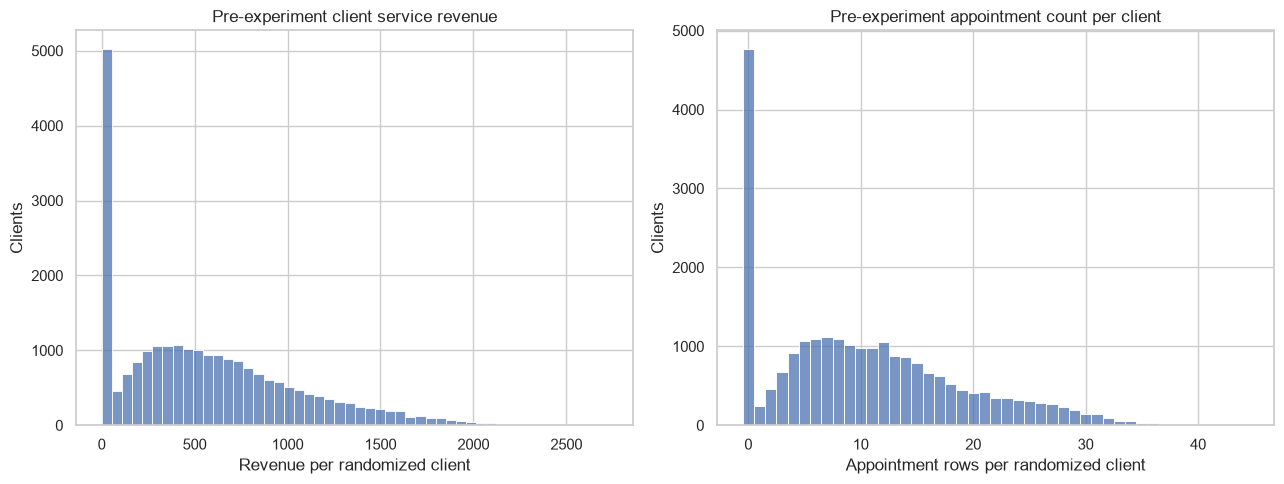

In [3]:
baseline_columns = [
    "baseline_service_revenue",
    "baseline_appointment_count",
    "baseline_completed_count",
    "signup_age_days_at_assignment",
    "retention_segment",
    "preferred_outlet_id",
]
missingness = analysis[baseline_columns].isna().sum().rename("missing_values").to_frame()
display(missingness)
display(analysis[[
    "baseline_service_revenue", "baseline_appointment_count",
    "baseline_completed_count", "signup_age_days_at_assignment",
]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).T.round(2))
display(analysis["retention_segment"].value_counts(dropna=False).rename("clients").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(analysis["baseline_service_revenue"], bins=50, ax=axes[0])
axes[0].set(title="Pre-experiment client service revenue",
            xlabel="Revenue per randomized client", ylabel="Clients")
sns.histplot(analysis["baseline_appointment_count"], discrete=True, ax=axes[1])
axes[1].set(title="Pre-experiment appointment count per client",
            xlabel="Appointment rows per randomized client", ylabel="Clients")
plt.tight_layout()
plt.show()

## 5. Unadjusted ITT estimate

Estimate the difference in group means using the client-level outcome. The 95% confidence interval uses Welch's unequal-variance standard error and degrees of freedom; the two-sided Welch t-test tests equality of means. Percentage lift is the difference relative to the Control mean and is undefined if that mean is zero.

In [4]:
ALPHA = 0.05

def welch_mean_effect(frame, outcome):
    treatment_values = frame.loc[frame["treatment"].eq(1), outcome].to_numpy(dtype=float)
    control_values = frame.loc[frame["treatment"].eq(0), outcome].to_numpy(dtype=float)
    if len(treatment_values) < 2 or len(control_values) < 2:
        raise ValueError("Both randomized groups need at least two observations.")
    mean_t = treatment_values.mean()
    mean_c = control_values.mean()
    difference = mean_t - mean_c
    variance_t = treatment_values.var(ddof=1)
    variance_c = control_values.var(ddof=1)
    se = np.sqrt(variance_t / len(treatment_values) + variance_c / len(control_values))
    df_num = (variance_t / len(treatment_values) + variance_c / len(control_values)) ** 2
    df_den = (
        (variance_t / len(treatment_values)) ** 2 / (len(treatment_values) - 1)
        + (variance_c / len(control_values)) ** 2 / (len(control_values) - 1)
    )
    degrees_freedom = df_num / df_den if df_den else np.inf
    critical = stats.t.ppf(1 - ALPHA / 2, degrees_freedom)
    test = stats.ttest_ind(
        treatment_values, control_values, equal_var=False, alternative="two-sided"
    )
    return {
        "n_treatment": len(treatment_values),
        "n_control": len(control_values),
        "mean_treatment": mean_t,
        "mean_control": mean_c,
        "effect": difference,
        "ci_low": difference - critical * se,
        "ci_high": difference + critical * se,
        "p_value": float(test.pvalue),
        "percentage_lift": 100 * difference / mean_c if mean_c != 0 else np.nan,
    }

unadjusted = welch_mean_effect(analysis, "experiment_service_revenue")
display(pd.DataFrame([unadjusted], index=["Unadjusted ITT"]).T.round(4))
print(
    f"Unadjusted Treatment-Control effect: {unadjusted['effect']:,.2f} per client "
    f"({unadjusted['percentage_lift']:.2f}% relative to Control)."
)

,Unadjusted ITT
n_treatment,12000.0000
n_control,12000.0000
mean_treatment,70.8505
mean_control,65.0227
effect,5.8278
ci_low,1.5486
ci_high,10.1070
p_value,0.0076
percentage_lift,8.9627


Unadjusted Treatment-Control effect: 5.83 per client (8.96% relative to Control).


## 6. CUPED adjustment

Compute `theta` from the pooled client-level sample covariance of experiment outcome and baseline service revenue divided by the baseline variance. Apply the specified adjustment, then use a Welch comparison of adjusted client outcomes for the estimate, 95% CI, and p-value. Because the same theta and baseline centering are applied to both groups, the adjusted outcome difference reflects baseline prognostic adjustment. Variance reduction compares the variance of all adjusted outcomes with the unadjusted outcome variance; it is descriptive and may be negative if adjustment adds noise.

In [5]:
Y = analysis["experiment_service_revenue"].to_numpy(dtype=float)
X = analysis["baseline_service_revenue"].to_numpy(dtype=float)
variance_x = np.var(X, ddof=1)
if variance_x <= 0:
    raise ValueError("Baseline service-revenue variance must be positive for CUPED.")
theta = np.cov(Y, X, ddof=1)[0, 1] / variance_x
analysis["cuped_adjusted_revenue"] = (
    analysis["experiment_service_revenue"]
    - theta * (analysis["baseline_service_revenue"] - analysis["baseline_service_revenue"].mean())
)
cuped = welch_mean_effect(analysis, "cuped_adjusted_revenue")
unadjusted_variance = analysis["experiment_service_revenue"].var(ddof=1)
cuped_variance = analysis["cuped_adjusted_revenue"].var(ddof=1)
cuped_variance_reduction = (
    100 * (1 - cuped_variance / unadjusted_variance)
    if unadjusted_variance > 0 else np.nan
)
cuped["theta"] = theta
cuped["variance_reduction_pct"] = cuped_variance_reduction
display(pd.DataFrame(
    [unadjusted, cuped],
    index=["Unadjusted ITT", "CUPED"],
).T.round(4))
print(f"CUPED theta: {theta:.4f}")
print(f"CUPED variance reduction: {cuped_variance_reduction:.2f}%.")

,Unadjusted ITT,CUPED
n_treatment,12000.0000,12000.0000
n_control,12000.0000,12000.0000
mean_treatment,70.8505,70.8133
mean_control,65.0227,65.0599
effect,5.8278,5.7534
ci_low,1.5486,1.4782
ci_high,10.1070,10.0285
p_value,0.0076,0.0084
percentage_lift,8.9627,8.8432
theta,NaN,0.0153


CUPED theta: 0.0153
CUPED variance reduction: 0.19%.


## 7. Client-level regression adjustment with HC3 errors

Fit OLS at the randomized-client level with Treatment assignment, pre-experiment service revenue, pre-experiment appointment count, signup age, retention segment, and preferred outlet region. The treatment coefficient is the adjusted mean difference under this linear specification. HC3 standard errors are robust to heteroskedasticity. We do not include experiment-period appointments, engagement, product sales, or any other post-treatment variable as a covariate.

In [6]:
outlets_path = RAW_DIR / "outlets.csv"
if not outlets_path.is_file():
    raise FileNotFoundError(f"Missing required raw CSV: {outlets_path.name}")
outlets = pd.read_csv(outlets_path)
region_map = outlets.set_index("outlet_id")["region"]
analysis["preferred_region"] = analysis["preferred_outlet_id"].map(region_map)
if analysis[["retention_segment", "preferred_region"]].isna().any().any():
    raise ValueError("Baseline categorical adjustment fields contain missing values.")

regression_formula = (
    "experiment_service_revenue ~ treatment + baseline_service_revenue "
    "+ baseline_appointment_count + signup_age_days_at_assignment "
    "+ C(retention_segment) + C(preferred_region)"
)
regression_model = smf.ols(regression_formula, data=analysis).fit(cov_type="HC3")
regression_ci = regression_model.conf_int().loc["treatment"]
regression = {
    "n_treatment": int(analysis["treatment"].sum()),
    "n_control": int((analysis["treatment"] == 0).sum()),
    "mean_treatment": analysis.loc[analysis["treatment"].eq(1), "experiment_service_revenue"].mean(),
    "mean_control": analysis.loc[analysis["treatment"].eq(0), "experiment_service_revenue"].mean(),
    "effect": float(regression_model.params["treatment"]),
    "ci_low": float(regression_ci.iloc[0]),
    "ci_high": float(regression_ci.iloc[1]),
    "p_value": float(regression_model.pvalues["treatment"]),
}
regression["percentage_lift"] = (
    100 * regression["effect"] / regression["mean_control"]
    if regression["mean_control"] else np.nan
)
display(pd.DataFrame([regression], index=["Regression HC3"]).T.round(4))
print("HC3 regression uses client-level rows and only pre-experiment covariates.")

,Regression HC3
n_treatment,12000.0000
n_control,12000.0000
mean_treatment,70.8505
mean_control,65.0227
effect,3.6117
ci_low,0.7554
ci_high,6.4680
p_value,0.0132
percentage_lift,5.5546


HC3 regression uses client-level rows and only pre-experiment covariates.


## 8. Robustness: estimates, skewness, and influential clients

Compare unadjusted, CUPED, and regression-adjusted effects on the same ITT scale. Examine outcome skewness and the share of total revenue from the top 1% of clients by group. As a sensitivity diagnostic, calculate the range of leave-one-client-out unadjusted effect estimates. This diagnostic does not remove any client from the reported analysis; every valid client remains in all primary estimates.

In [7]:
def leave_one_out_effect_range(frame, outcome):
    treatment_values = frame.loc[frame["treatment"].eq(1), outcome].to_numpy(dtype=float)
    control_values = frame.loc[frame["treatment"].eq(0), outcome].to_numpy(dtype=float)
    mean_t, mean_c = treatment_values.mean(), control_values.mean()
    effects_without_t = (
        (treatment_values.sum() - treatment_values) / (len(treatment_values) - 1) - mean_c
    )
    effects_without_c = mean_t - (
        (control_values.sum() - control_values) / (len(control_values) - 1)
    )
    all_leave_one_out = np.concatenate([effects_without_t, effects_without_c])
    index = np.argmax(np.abs(all_leave_one_out - (mean_t - mean_c)))
    return {
        "full_sample_effect": mean_t - mean_c,
        "minimum_leave_one_out_effect": all_leave_one_out.min(),
        "maximum_leave_one_out_effect": all_leave_one_out.max(),
        "largest_absolute_change": np.abs(
            all_leave_one_out[index] - (mean_t - mean_c)
        ),
    }

influence = leave_one_out_effect_range(analysis, "experiment_service_revenue")
diagnostic_rows = []
for group in ["Control", "Treatment"]:
    values = analysis.loc[
        analysis["assignment_group"].eq(group), "experiment_service_revenue"
    ]
    top_n = max(1, int(np.ceil(0.01 * len(values))))
    top_revenue_share = values.nlargest(top_n).sum() / values.sum()
    diagnostic_rows.append({
        "group": group,
        "mean": values.mean(),
        "median": values.median(),
        "skewness": stats.skew(values, bias=False),
        "zero_share": values.eq(0).mean(),
        "top_1pct_revenue_share": top_revenue_share,
        "maximum_client_revenue": values.max(),
    })
display(pd.DataFrame(diagnostic_rows).set_index("group").round(3))
display(pd.DataFrame([influence], index=["Leave-one-client-out range"]).T.round(3))

# Optional robustness: winsorize at a pooled 99th percentile, retaining every client.
# This changes the outcome definition and is a sensitivity check only.
winsor_limit = analysis["experiment_service_revenue"].quantile(0.99)
analysis["winsorized_revenue_p99"] = analysis["experiment_service_revenue"].clip(
    upper=winsor_limit
)
winsorized = welch_mean_effect(analysis, "winsorized_revenue_p99")
robustness_table = pd.DataFrame(
    [
        {"analysis": "Original outcome, unadjusted", **unadjusted},
        {"analysis": "Pooled 99th-percentile winsorized outcome", **winsorized},
    ]
).set_index("analysis")
display(robustness_table[[
    "n_treatment", "n_control", "mean_treatment", "mean_control",
    "effect", "ci_low", "ci_high", "p_value", "percentage_lift",
]].round(4))
print(
    f"Winsorization threshold: {winsor_limit:,.2f}. All clients remain; this "
    "sensitivity changes extreme outcome values and therefore the estimand."
)

,mean,median,skewness,zero_share,top_1pct_revenue_share,maximum_client_revenue
group,,,,,,
Control,65.023,0.0,3.644,0.771,0.159,1926.10
Treatment,70.851,0.0,3.360,0.761,0.147,1606.97


,Leave-one-client-out range
full_sample_effect,5.828
minimum_leave_one_out_effect,5.700
maximum_leave_one_out_effect,5.983
largest_absolute_change,0.155


,n_treatment,n_control,mean_treatment,mean_control,effect,ci_low,ci_high,p_value,percentage_lift
analysis,,,,,,,,,
"Original outcome, unadjusted",12000,12000,70.8505,65.0227,5.8278,1.5486,10.107,0.0076,8.9627
Pooled 99th-percentile winsorized outcome,12000,12000,68.5898,62.8566,5.7332,1.7804,9.686,0.0045,9.1211


Winsorization threshold: 816.04. All clients remain; this sensitivity changes extreme outcome values and therefore the estimand.


## 9. Visualizations

The baseline/outcome scatter uses `log1p` axes to display zero-heavy, skewed client revenue without discarding observations. The outcome distributions are shown on the original revenue scale with a capped display range only for readability; no values are removed from estimation. The effect plot compares confidence intervals on the original currency-per-client scale. The variance plot compares raw outcome variance with the CUPED-adjusted variance.

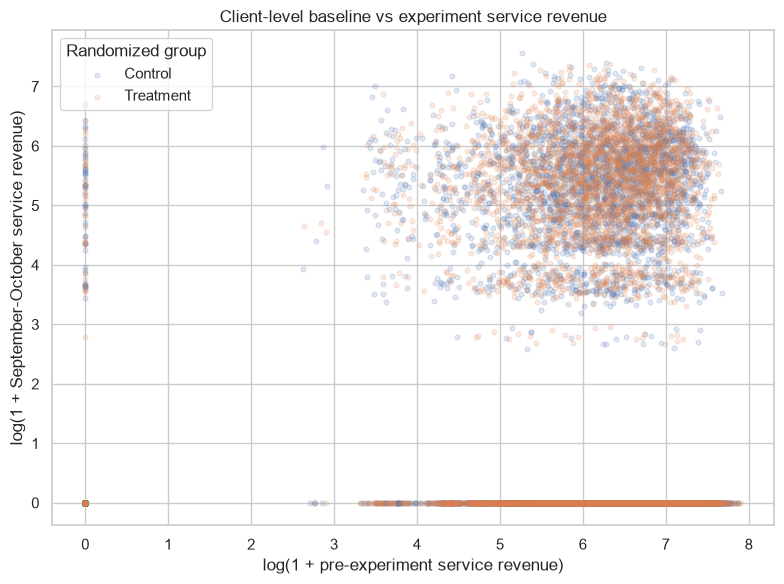

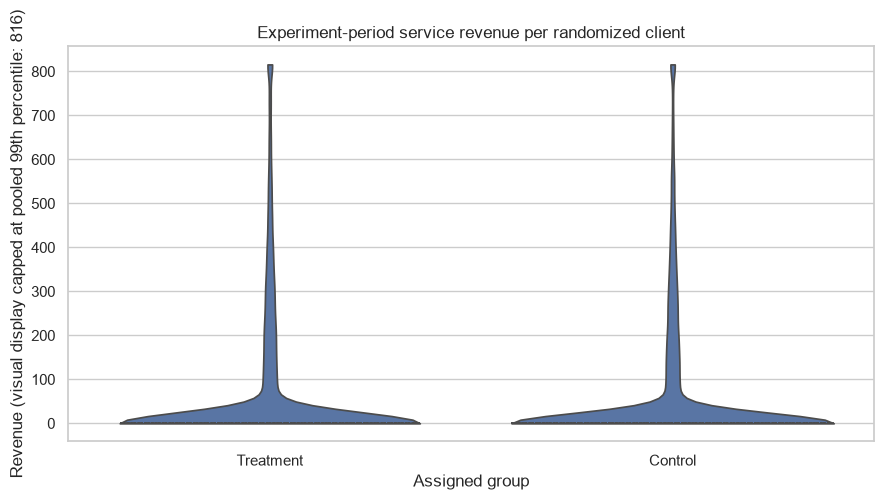

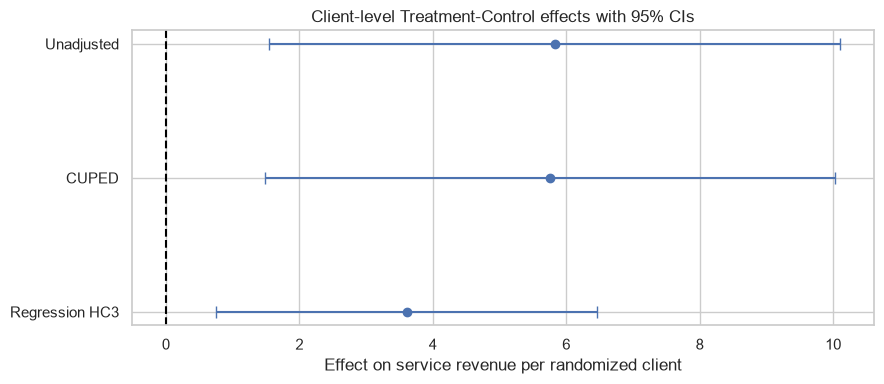

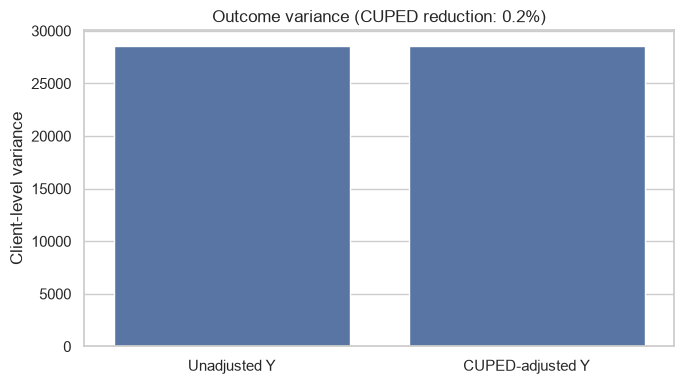

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
for group, color in zip(["Control", "Treatment"], sns.color_palette()[:2]):
    subset = analysis.loc[analysis["assignment_group"].eq(group)]
    ax.scatter(
        np.log1p(subset["baseline_service_revenue"]),
        np.log1p(subset["experiment_service_revenue"]),
        alpha=0.16, s=12, label=group, color=color,
    )
ax.set(
    title="Client-level baseline vs experiment service revenue",
    xlabel="log(1 + pre-experiment service revenue)",
    ylabel="log(1 + September-October service revenue)",
)
ax.legend(title="Randomized group")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
display_cap = analysis["experiment_service_revenue"].quantile(0.99)
plot_data = analysis.assign(
    revenue_for_display=analysis["experiment_service_revenue"].clip(upper=display_cap)
)
sns.violinplot(
    data=plot_data, x="assignment_group", y="revenue_for_display",
    inner="quartile", cut=0, ax=ax,
)
ax.set(
    title="Experiment-period service revenue per randomized client",
    xlabel="Assigned group",
    ylabel=f"Revenue (visual display capped at pooled 99th percentile: {display_cap:,.0f})",
)
plt.tight_layout()
plt.show()

effect_rows = [
    {"method": "Unadjusted", "estimate": unadjusted["effect"],
     "low": unadjusted["ci_low"], "high": unadjusted["ci_high"]},
    {"method": "CUPED", "estimate": cuped["effect"],
     "low": cuped["ci_low"], "high": cuped["ci_high"]},
    {"method": "Regression HC3", "estimate": regression["effect"],
     "low": regression["ci_low"], "high": regression["ci_high"]},
]
effect_plot = pd.DataFrame(effect_rows)
fig, ax = plt.subplots(figsize=(9, 4))
y_positions = np.arange(len(effect_plot))
ax.errorbar(
    effect_plot["estimate"], y_positions,
    xerr=[
        effect_plot["estimate"] - effect_plot["low"],
        effect_plot["high"] - effect_plot["estimate"],
    ],
    fmt="o", capsize=4,
)
ax.axvline(0, color="black", linestyle="--")
ax.set_yticks(y_positions)
ax.set_yticklabels(effect_plot["method"])
ax.invert_yaxis()
ax.set(title="Client-level Treatment-Control effects with 95% CIs",
       xlabel="Effect on service revenue per randomized client")
plt.tight_layout()
plt.show()

variance_plot = pd.DataFrame({
    "outcome": ["Unadjusted Y", "CUPED-adjusted Y"],
    "variance": [unadjusted_variance, cuped_variance],
})
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=variance_plot, x="outcome", y="variance", ax=ax)
ax.set(title=f"Outcome variance (CUPED reduction: {cuped_variance_reduction:.1f}%)",
       xlabel="", ylabel="Client-level variance")
plt.tight_layout()
plt.show()

## 10. Sensitivity using pre-policy covariates only

The primary baseline uses all appointments before September 1, including July–August after the policy began. To check robustness, re-estimate the covariate-adjusted regression using baseline service revenue and appointment counts from **November 2025–June 2026 only**, before the policy start. Keep the same full randomized cohort and experiment outcome. This tests sensitivity to the later baseline window; it does not change the randomized ITT population or prove the model is correctly specified.

In [9]:
PRE_POLICY_START = pd.Timestamp("2025-11-01")
POLICY_START = pd.Timestamp("2026-07-01")
pre_policy_appointments = appointments.loc[
    appointments["appointment_date"].between(
        PRE_POLICY_START, POLICY_START - pd.Timedelta(days=1)
    )
    & appointments["client_id"].notna()
]
pre_policy_covariates = pre_policy_appointments.groupby("client_id").agg(
    pre_policy_appointment_count=("appointment_id", "size"),
    pre_policy_service_revenue=("appointment_revenue", "sum"),
)
sensitivity = (
    analysis.drop(columns=["pre_policy_appointment_count", "pre_policy_service_revenue"], errors="ignore")
    .merge(pre_policy_covariates, on="client_id", how="left", validate="one_to_one")
)
sensitivity[["pre_policy_appointment_count", "pre_policy_service_revenue"]] = (
    sensitivity[["pre_policy_appointment_count", "pre_policy_service_revenue"]].fillna(0)
)
sensitivity["pre_policy_appointment_count"] = sensitivity[
    "pre_policy_appointment_count"
].astype(int)

pre_policy_formula = (
    "experiment_service_revenue ~ treatment + pre_policy_service_revenue "
    "+ pre_policy_appointment_count + signup_age_days_at_assignment "
    "+ C(retention_segment) + C(preferred_region)"
)
pre_policy_model = smf.ols(pre_policy_formula, data=sensitivity).fit(cov_type="HC3")
pre_policy_ci = pre_policy_model.conf_int().loc["treatment"]
pre_policy_adjusted = {
    "method": "Regression HC3 (pre-policy covariates)",
    "estimate": float(pre_policy_model.params["treatment"]),
    "ci_low": float(pre_policy_ci.iloc[0]),
    "ci_high": float(pre_policy_ci.iloc[1]),
    "p_value": float(pre_policy_model.pvalues["treatment"]),
    "n_clients": len(sensitivity),
}
display(pd.DataFrame([pre_policy_adjusted]).set_index("method").round(4))
assert len(sensitivity) == 24_000 and sensitivity["client_id"].is_unique

,estimate,ci_low,ci_high,p_value,n_clients
method,,,,,
Regression HC3 (pre-policy covariates),3.4342,0.7112,6.1573,0.0134,24000


## 11. Final comparison and interpretation

Compare the estimates and intervals on the same client-level outcome; do not select a method because it gives a preferred result. A narrower interval indicates greater precision under that method's assumptions, not greater validity. The summary uses calculated results and does not apply a GO/NO-GO threshold.

In [10]:
comparison = pd.DataFrame([
    {
        "method": "Unadjusted Welch",
        "effect": unadjusted["effect"],
        "ci_low": unadjusted["ci_low"],
        "ci_high": unadjusted["ci_high"],
        "p_value": unadjusted["p_value"],
        "relative_lift_pct": unadjusted["percentage_lift"],
    },
    {
        "method": "CUPED Welch",
        "effect": cuped["effect"],
        "ci_low": cuped["ci_low"],
        "ci_high": cuped["ci_high"],
        "p_value": cuped["p_value"],
        "relative_lift_pct": cuped["percentage_lift"],
    },
    {
        "method": "Regression HC3",
        "effect": regression["effect"],
        "ci_low": regression["ci_low"],
        "ci_high": regression["ci_high"],
        "p_value": regression["p_value"],
        "relative_lift_pct": regression["percentage_lift"],
    },
    {
        "method": pre_policy_adjusted["method"],
        "effect": pre_policy_adjusted["estimate"],
        "ci_low": pre_policy_adjusted["ci_low"],
        "ci_high": pre_policy_adjusted["ci_high"],
        "p_value": pre_policy_adjusted["p_value"],
        "relative_lift_pct": 100 * pre_policy_adjusted["estimate"] / unadjusted["mean_control"],
    },
])
comparison = comparison.set_index("method")
display(comparison.round(4))

width_unadjusted = unadjusted["ci_high"] - unadjusted["ci_low"]
width_cuped = cuped["ci_high"] - cuped["ci_low"]
precision_change = 100 * (1 - width_cuped / width_unadjusted)
print("### Interpretation")
print(
    f"Unadjusted difference: {unadjusted['effect']:,.2f} per randomized client "
    f"(95% CI {unadjusted['ci_low']:,.2f} to {unadjusted['ci_high']:,.2f}; "
    f"Welch p={unadjusted['p_value']:.4g})."
)
print(
    f"CUPED difference: {cuped['effect']:,.2f} "
    f"(95% CI {cuped['ci_low']:,.2f} to {cuped['ci_high']:,.2f}; "
    f"p={cuped['p_value']:.4g}); variance reduction={cuped_variance_reduction:.2f}%."
)
print(
    f"Regression HC3 difference: {regression['effect']:,.2f} "
    f"(95% CI {regression['ci_low']:,.2f} to {regression['ci_high']:,.2f}; "
    f"p={regression['p_value']:.4g})."
)
print(f"CUPED interval width change vs unadjusted: {precision_change:.2f}% (positive means narrower).")
print(
    "Assess consistency by comparing signs, magnitudes, and interval overlap in the table; "
    "adjustment changes precision and can shift estimates due to finite-sample imbalance."
)
print(
    "No valid clients were removed for zero or high revenue. The winsorized result is a "
    "separately labeled outcome sensitivity, not the primary estimate."
)
print(
    "All estimates describe fictional synthetic data. The generator's artificial effects "
    "are not empirical evidence, and no real-world causal or business conclusion follows."
)
print(
    "Required assumptions include client-level randomized assignment as recorded, valid "
    "pre-experiment covariates, consistent measurement, and no interference. The A/B "
    "window also overlaps the simulated outlet-policy period."
)

,effect,ci_low,ci_high,p_value,relative_lift_pct
method,,,,,
Unadjusted Welch,5.8278,1.5486,10.1070,0.0076,8.9627
CUPED Welch,5.7534,1.4782,10.0285,0.0084,8.8432
Regression HC3,3.6117,0.7554,6.4680,0.0132,5.5546
Regression HC3 (pre-policy covariates),3.4342,0.7112,6.1573,0.0134,5.2816


### Interpretation
Unadjusted difference: 5.83 per randomized client (95% CI 1.55 to 10.11; Welch p=0.007604).
CUPED difference: 5.75 (95% CI 1.48 to 10.03; p=0.00835); variance reduction=0.19%.
Regression HC3 difference: 3.61 (95% CI 0.76 to 6.47; p=0.0132).
CUPED interval width change vs unadjusted: 0.09% (positive means narrower).
Assess consistency by comparing signs, magnitudes, and interval overlap in the table; adjustment changes precision and can shift estimates due to finite-sample imbalance.
No valid clients were removed for zero or high revenue. The winsorized result is a separately labeled outcome sensitivity, not the primary estimate.
All estimates describe fictional synthetic data. The generator's artificial effects are not empirical evidence, and no real-world causal or business conclusion follows.
Required assumptions include client-level randomized assignment as recorded, valid pre-experiment covariates, consistent measurement, and no interference. The A/B window also 